# MosaicFormer Pretraining and Research Experiments

This notebook follows the same experimental rhythm as your GPT pretraining notebook: load data, build dataloaders, train, calculate loss, generate text, and compare results.

In [2]:
import sys
from pathlib import Path

CANDIDATES = [
    Path.cwd(),
    Path.cwd() / 'MosaicFormer',
    Path.cwd().parent,
    Path.cwd().parent / 'MosaicFormer',
    Path.cwd().parent.parent / 'MosaicFormer',
]
PROJECT_DIR = next((path for path in CANDIDATES if (path / 'model.py').exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Open this notebook from the LLM folder or the MosaicFormer folder.')
sys.path.insert(0, str(PROJECT_DIR.resolve()))

import math
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import tiktoken

from baseline import GPTModel
from data import create_dataloader, make_needle_recall_data, split_token_ids
from model import MosaicFormerModel, make_mosaic_config
from train_utils import (
    count_parameters, evaluate_needle_recall, generate, text_to_token_ids,
    token_ids_to_text, train_model, train_needle_recall_task,
)

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


## 1. Load data and create GPT-style dataloaders

In [5]:
# DATA_PATH = PROJECT_DIR.parent / 'the-verdict.txt'
DATA_PATH = PROJECT_DIR.parent /'GPT'/ 'tinystories_1000.txt'

# For a larger second run, use: PROJECT_DIR.parent / 'GPT' / 'tinystories_1000.txt'
text_data = DATA_PATH.read_text(encoding='utf-8')
tokenizer = tiktoken.get_encoding('gpt2')
token_ids = tokenizer.encode(text_data, allowed_special='all')
print('Characters:', len(text_data))
print('Tokens:', len(token_ids))
print(text_data[:250])

Characters: 958623
Tokens: 238416
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, 


In [6]:
CONFIG = make_mosaic_config(tokenizer.n_vocab)
BATCH_SIZE = 2
STRIDE = CONFIG['context_length']
train_ids, val_ids = split_token_ids(token_ids, train_ratio=0.8)
train_loader = create_dataloader(train_ids, CONFIG['context_length'], STRIDE, BATCH_SIZE, True, True)
val_loader = create_dataloader(val_ids, CONFIG['context_length'], STRIDE, BATCH_SIZE, False, True)
print('Train batches:', len(train_loader))
print('Validation batches:', len(val_loader))
CONFIG

Train batches: 93
Validation batches: 23


{'vocab_size': 50257,
 'context_length': 1024,
 'emb_dim': 768,
 'n_heads': 12,
 'n_layers': 12,
 'dropout': 0.1,
 'qkv_bias': False,
 'chunk_size': 128,
 'window_size': 128,
 'num_memory_tokens': 16,
 'max_memory_chunks': 8,
 'use_memory': True,
 'use_gate': True}

## 2. Experiment controls

Keep these values identical for every experiment. This makes the comparison fair. Start with `NUM_EPOCHS = 10` to check the pipeline, then use more epochs for your final results.

In [4]:
NUM_EPOCHS = 2
EVAL_FREQ = 5
EVAL_ITER = 3
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1

In [5]:
def run_experiment(name, model):
    print(f'\n========== {name} ==========' )
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    results = train_model(
        model, train_loader, val_loader, optimizer, device,
        NUM_EPOCHS, EVAL_FREQ, EVAL_ITER
    )
    print(f"Final val loss: {results['final_val_loss']:.4f}")
    print(f"Perplexity: {results['perplexity']:.2f}")
    print(f"Peak GPU memory: {results['peak_gpu_mem_gb']:.3f} GB")
    # print(f"Model parameters{model.numel()}")
    return model, results

## 3. Train the baseline full-attention GPT

In [6]:
torch.manual_seed(42)
baseline_model, baseline_results = run_experiment('Baseline GPT (full attention)', GPTModel(CONFIG.copy()))


========== Baseline GPT (full attention) ==========
Epoch 1 Step 0: train loss 10.2710, val loss 10.2746
Epoch 1 Step 5: train loss 8.5688, val loss 8.6310
Epoch 1 Step 10: train loss 7.6778, val loss 7.6470
Epoch 1 Step 15: train loss 6.9743, val loss 6.8260
Epoch 1 Step 20: train loss 6.3849, val loss 6.2620
Epoch 1 Step 25: train loss 6.0155, val loss 5.9326
Epoch 1 Step 30: train loss 5.7820, val loss 5.7215
Epoch 1 Step 35: train loss 5.7102, val loss 5.5290
Epoch 1 Step 40: train loss 5.3791, val loss 5.3323
Epoch 1 Step 45: train loss 5.2386, val loss 5.1969
Epoch 1 Step 50: train loss 5.2744, val loss 5.0671
Epoch 1 Step 55: train loss 5.2263, val loss 4.9697
Epoch 1 Step 60: train loss 5.0784, val loss 4.8978
Epoch 1 Step 65: train loss 5.0484, val loss 4.8232
Epoch 1 Step 70: train loss 4.8897, val loss 4.7762
Epoch 1 Step 75: train loss 4.8919, val loss 4.6965
Epoch 1 Step 80: train loss 4.7917, val loss 4.6311
Epoch 1 Step 85: train loss 4.9263, val loss 4.5930
Epoch 1 Ste

In [9]:
total_params =0
for param in baseline_model.parameters():
    total_params += param.numel()
print(f"Total parameters in baseline model: {total_params/1e6:.2f}M")

Total parameters in baseline model: 77.20M


## 4. Train full MosaicFormer

In [8]:
torch.manual_seed(42)
mosaic_model, mosaic_results = run_experiment('MosaicFormer (local + memory + gate)', MosaicFormerModel(CONFIG.copy()))


========== MosaicFormer (local + memory + gate) ==========
Epoch 1 Step 0: train loss 10.3428, val loss 10.3035
Epoch 1 Step 5: train loss 8.6554, val loss 8.7143
Epoch 1 Step 10: train loss 7.7840, val loss 7.8105
Epoch 1 Step 15: train loss 6.8220, val loss 6.8806
Epoch 1 Step 20: train loss 6.4212, val loss 6.2710
Epoch 1 Step 25: train loss 5.9803, val loss 5.9078
Epoch 1 Step 30: train loss 5.7592, val loss 5.6437
Epoch 1 Step 35: train loss 5.5260, val loss 5.4381
Epoch 1 Step 40: train loss 5.4579, val loss 5.3031
Epoch 1 Step 45: train loss 5.2507, val loss 5.1424
Epoch 1 Step 50: train loss 5.1559, val loss 5.0231
Epoch 1 Step 55: train loss 5.1365, val loss 4.9195
Epoch 1 Step 60: train loss 4.8396, val loss 4.8284
Epoch 1 Step 65: train loss 4.9266, val loss 4.7289
Epoch 1 Step 70: train loss 5.0412, val loss 4.6709
Epoch 1 Step 75: train loss 4.7914, val loss 4.6024
Epoch 1 Step 80: train loss 4.8671, val loss 4.5178
Epoch 1 Step 85: train loss 4.7589, val loss 4.4754
Epoc

## 5. Ablations

Run these for a research-style answer to: *which component actually helps?*

In [10]:
RUN_ABLATIONS = True

if RUN_ABLATIONS:
    torch.manual_seed(42)
    local_only_cfg = make_mosaic_config(tokenizer.n_vocab, use_memory=False)
    local_only_model, local_only_results = run_experiment('MosaicFormer local only', MosaicFormerModel(local_only_cfg))

    torch.manual_seed(42)
    no_gate_cfg = make_mosaic_config(tokenizer.n_vocab, use_memory=True, use_gate=False)
    no_gate_model, no_gate_results = run_experiment('MosaicFormer memory without gate', MosaicFormerModel(no_gate_cfg))
    # torch.manual_seed(42)
    # gate_cfg = make_mosaic_config(tokenizer.n_vocab, use_memory=True, use_gate=True)
    # gate_model, gate_results = run_experiment('MosaicFormer memory with gate', MosaicFormerModel(gate_cfg))


========== MosaicFormer local only ==========
Epoch 1 Step 0: train loss 10.3403, val loss 10.3007
Epoch 1 Step 5: train loss 8.6089, val loss 8.6679
Epoch 1 Step 10: train loss 7.7262, val loss 7.7420
Epoch 1 Step 15: train loss 6.8059, val loss 6.8787
Epoch 1 Step 20: train loss 6.4213, val loss 6.2726
Epoch 1 Step 25: train loss 6.0068, val loss 5.9473
Epoch 1 Step 30: train loss 5.8294, val loss 5.7431
Epoch 1 Step 35: train loss 5.6325, val loss 5.5892
Epoch 1 Step 40: train loss 5.5374, val loss 5.4108
Epoch 1 Step 45: train loss 5.3396, val loss 5.2379
Epoch 1 Step 50: train loss 5.2555, val loss 5.1221
Epoch 1 Step 55: train loss 5.2208, val loss 5.0131
Epoch 1 Step 60: train loss 4.9237, val loss 4.9192
Epoch 1 Step 65: train loss 5.0083, val loss 4.8061
Epoch 1 Step 70: train loss 5.0922, val loss 4.7526
Epoch 1 Step 75: train loss 4.8559, val loss 4.6620
Epoch 1 Step 80: train loss 4.9264, val loss 4.5689
Epoch 1 Step 85: train loss 4.8058, val loss 4.5226
Epoch 1 Step 90: 

## 6. Compare loss, perplexity, time, memory, and parameters

In [11]:
all_results = [('Baseline GPT', baseline_results), ('MosaicFormer full', mosaic_results)]
if RUN_ABLATIONS:
    all_results.extend([
        ('MosaicFormer local only', local_only_results),
        ('MosaicFormer memory without gate', no_gate_results)
        # ('MosaicFormer memory with gate', gate_results)
    ])

comparison = pd.DataFrame([{
    'Model': name,
    'Parameters (M)': results['num_params'] / 1e6,
    'Validation Loss': results['final_val_loss'],
    'Perplexity': results['perplexity'],
    'Train Time (s)': results['elapsed_sec'],
    'Peak GPU Memory (GB)': results['peak_gpu_mem_gb'],
} for name, results in all_results])
RESULT_DIR = PROJECT_DIR / 'RESULT'
RESULT_DIR.mkdir(exist_ok=True)
RUN_TIMESTAMP = datetime.now().strftime('%Y%m%d_%H%M%S')
comparison.to_csv(RESULT_DIR / f'experiment_results_2_{RUN_TIMESTAMP}.csv', index=False)
comparison

,Model,Parameters (M),Validation Loss,Perplexity,Train Time (s),Peak GPU Memory (GB)
0,Baseline GPT,77.195264,4.392872,80.872322,280.868232,4.537959
1,MosaicFormer full,94.054400,4.263823,71.081216,1189.901411,4.747716
2,MosaicFormer local only,94.054400,4.312846,74.652667,908.009664,4.929701
3,MosaicFormer memory without gate,94.054400,4.283345,72.482494,1426.552308,5.987984


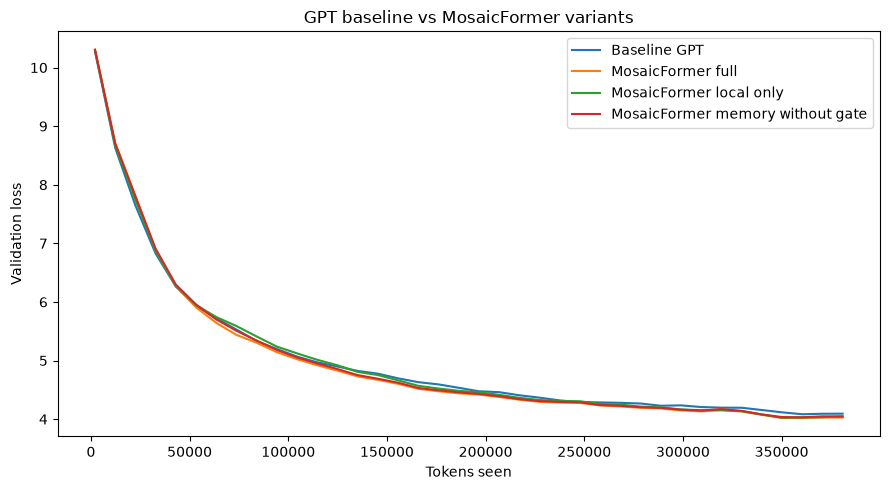

In [12]:
plt.figure(figsize=(9, 5))
for name, results in all_results:
    plt.plot(results['track_tokens_seen'], results['val_losses'], label=name)
plt.xlabel('Tokens seen')
plt.ylabel('Validation loss')
plt.title('GPT baseline vs MosaicFormer variants')
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / f'mosaicformer_experiment_loss_2_{RUN_TIMESTAMP}.png', dpi=150)
plt.show()

## 7. Generate samples

In [13]:
prompt = 'The picture was'
start_ids = text_to_token_ids(prompt, tokenizer).to(device)

baseline_out = generate(baseline_model, start_ids, 40, CONFIG['context_length'])
mosaic_out = generate(mosaic_model, start_ids, 40, CONFIG['context_length'])

print('Baseline GPT:\n', token_ids_to_text(baseline_out, tokenizer))
print('\nMosaicFormer:\n', token_ids_to_text(mosaic_out, tokenizer))

Baseline GPT:
 The picture was so he had a little to help, the woods! He was a little girl was so excited.

Once upon a time there was a time there was very scared and was a little girl.

MosaicFormer:
 The picture was very happy and ran away.
"My. One day, they would go to help them and asked her home. She smiled, and it. The sun, we do his friends. They put


## 8. Future research step: synthetic long-context recall

This controlled task puts a key-value fact near the beginning and asks for the value at the end. Train fresh models on this task, then report final-token accuracy. It isolates long-context memory from normal language fluency.

In [7]:
RUN_RECALL_EXPERIMENT = True  # change to True after the language-model experiment works
recall_inputs, recall_targets = make_needle_recall_data(256, CONFIG['context_length'], 128)
print('Recall inputs:', recall_inputs.shape)
print('Recall targets:', recall_targets.shape)

if RUN_RECALL_EXPERIMENT:
    toy_cfg = make_mosaic_config(vocab_size=128)
    torch.manual_seed(42)
    recall_baseline = GPTModel(toy_cfg).to(device)
    baseline_accuracy = train_needle_recall_task(recall_baseline, recall_inputs, recall_targets, device)

    torch.manual_seed(42)
    recall_mosaic = MosaicFormerModel(toy_cfg).to(device)
    mosaic_accuracy = train_needle_recall_task(recall_mosaic, recall_inputs, recall_targets, device)

    print('Baseline recall accuracy:', baseline_accuracy)
    print('MosaicFormer recall accuracy:', mosaic_accuracy)

Recall inputs: torch.Size([256, 1024])
Recall targets: torch.Size([256])


OutOfMemoryError: CUDA out of memory. Tried to allocate 1.50 GiB. GPU 0 has a total capacity of 4.00 GiB of which 0 bytes is free. Of the allocated memory 9.27 GiB is allocated by PyTorch, and 81.63 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

## Final-report checklist

- Run every condition with the same tokenizer, data split, context length, learning rate, and training tokens.
- Repeat the final experiment with three seeds: 42, 123, and 999.
- Report mean and standard deviation for loss, perplexity, time, GPU memory, and recall accuracy.
- Start on The Verdict, then rerun on TinyStories for a more credible result.
- Explain both outcomes honestly: whether the memory path helps, hurts, or trades quality for efficiency.